In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.constants import physical_constants
from scipy.optimize import curve_fit
import pandas as pd
from scipy.signal import find_peaks
from lpsd import lpsd
from scipy.stats import linregress  
from scipy.signal import welch
from scipy.special import voigt_profile

# Laser frequency stabilization: student worksheet

In this hands-on session, you will use experimental data to study laser-frequency stabilization with the [Pound-Drever-Hall (PDH) technique](https://doi.org/10.1364/OL.19.000898). You will characterize a reference cavity, calibrate the PDH discriminator, investigate feedback-loop bandwidth, and estimate the measured laser linewidth.

The notebook is deliberately structured as a sequence of short analyses. Read each prompt before running the following cell, record important values with units, and compare your interpretation with the plots. The relevant data are in [`../data/`](../data/).

The laser is a diode laser near 493 nm, used to drive the $S_{1/2} \rightarrow P_{1/2}$ transition in $^{138}\mathrm{Ba}^+$ ions. The atomic transition has a linewidth of approximately 20 MHz, much broader than the laser linewidth measured here, which is of order 100 kHz. The lock is therefore mainly used to keep the laser frequency centered over time.

Keep track of units: cavity scans are calibrated in MHz, while the frequency-noise analysis ultimately uses Hz.

# Cavity properties

An optical cavity provides a frequency reference for the laser lock. In this section, characterize the cavity's free spectral range (FSR), resonance linewidth, length, and finesse.

The **free spectral range** is the frequency spacing between adjacent longitudinal modes:

$$\mathrm{FSR} = \frac{c}{2L},$$

where $c$ is the speed of light and $L$ is the cavity length. The **cavity linewidth** $\Delta\nu$ is the full width at half maximum (FWHM) of one resonance. The **finesse** is

$$\mathcal{F} = \frac{\mathrm{FSR}}{\Delta\nu}.$$

Use the transmission scans in [`../data/cavity-properties/`](../data/cavity-properties/) for the following analysis.

In [2]:
c = physical_constants['speed of light in vacuum'][0]

folder = '../data/cavity-properties'
df_wide = pd.read_csv(f'{folder}/wide-scan.csv', delimiter=';')
df_narrow = pd.read_csv(f'{folder}/narrow-scan.csv', delimiter=';')

# normalize and massage the data 
transmission_narrow = (df_narrow['transmission-voltage'] - np.min(df_narrow['transmission-voltage'])) / (np.max(df_narrow['transmission-voltage']) - np.min(df_narrow['transmission-voltage']))
pdh_error_narrow = df_narrow['pdh-error'] / np.max(np.abs(df_narrow['pdh-error']))
piezo_voltage_narrow = df_narrow['piezo-voltage']
piezo_voltage_center = piezo_voltage_narrow[np.argmax(transmission_narrow)]
piezo_voltage_narrow = piezo_voltage_narrow - piezo_voltage_center

transmission_wide = (df_wide['transmission-voltage'] - np.min(df_wide['transmission-voltage'])) / (np.max(df_wide['transmission-voltage']) - np.min(df_wide['transmission-voltage']))
pdh_error_wide = df_wide['pdh-error'] / np.max(np.abs(df_wide['pdh-error']))
piezo_voltage_wide = df_wide['piezo-voltage']
piezo_voltage_center = piezo_voltage_wide[np.argmax(transmission_wide[:len(transmission_wide)//2])]
piezo_voltage_wide = piezo_voltage_wide - piezo_voltage_center

## Inspect the cavity scans

The code cell below plots the normalized transmission and PDH error signals against piezo voltage for both a narrow and a wide scan.

**Questions to consider:** Which scan is best for measuring the cavity linewidth? Which scan is best for measuring the FSR? What features identify the carrier, sidebands, and neighboring cavity resonances?

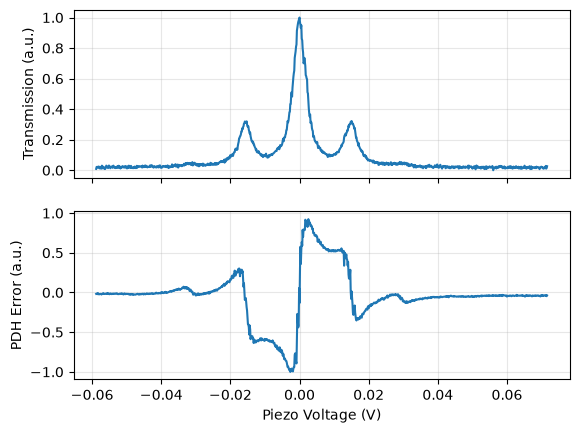

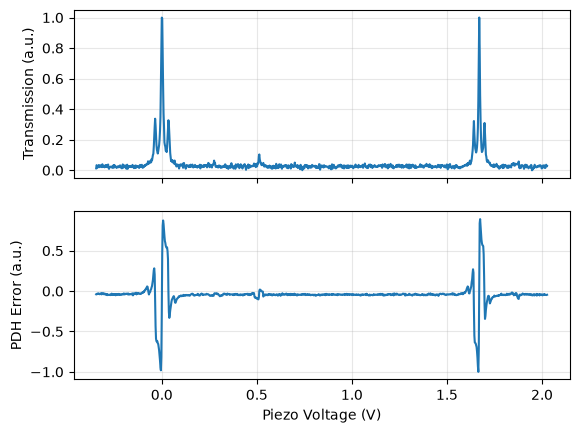

In [3]:
# plot the transmission and PDH error signals
fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_narrow, transmission_narrow)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_narrow, pdh_error_narrow)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_wide, transmission_wide)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_wide, pdh_error_wide)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()

## Convert piezo voltage to frequency

The piezo voltage scans the laser across the cavity resonances, but the horizontal axis we need is frequency. The modulation sidebands are separated from the carrier by 25 MHz, so they provide a frequency reference.

Use the transmission peaks to determine the sideband spacing in piezo voltage for each scan. Then convert both piezo-voltage axes to frequency in MHz. Inspect the selected peak markers and check that the carrier is centered as expected.

**Questions to consider:** Why is a sideband spacing useful for calibration? What assumption are you making when you use one average voltage spacing as a linear conversion factor?

In [4]:
# TODO: identify the carrier and sideband peaks in each scan.
sideband_spacing_frequency = 25  # MHz

# Hint: use scipy.signal.find_peaks with suitable height and distance values.
# peak_indicies_narrow = ...
# peak_indicies_wide = ...

# Plot the selected peaks on both scans and check that the markers are sensible.

# TODO: calculate the mean sideband spacing in piezo voltage.
# sideband_spacing_voltage_narrow = ...
# sideband_spacing_voltage_wide = ...

# TODO: convert both piezo-voltage axes to frequency axes in MHz.
# frequency_narrow = ...
# frequency_wide = ...

## Plot the calibrated transmission and error signals

After completing the calibration code above, plot both scans against frequency. Use these plots to check the calibration before fitting or extracting cavity parameters.

## Analyse the transmission spectra

### Cavity linewidth

Fit the central transmission peak in the narrow scan with a Lorentzian. Choose a fitting window that excludes the modulation sidebands, then extract the linewidth from the fitted half-width parameter.

Remember that the reported linewidth is the **full** width at half maximum, so it is twice the Lorentzian half-width. Use the covariance matrix from `curve_fit` to estimate the uncertainty.

In [5]:
# TODO: choose a fitting window around the central cavity resonance.
# TODO: define a Lorentzian model with a center, half-width, and amplitude.
# TODO: fit the selected transmission data with scipy.optimize.curve_fit.
# TODO: calculate the FWHM and its uncertainty from the fit covariance matrix.

# Use the variables above to plot the data and your fitted curve.

### Cavity FSR, length, and finesse

Use adjacent transmission peaks in the wide scan to determine the FSR. Then use

$$L = \frac{c}{2\,\mathrm{FSR}}$$

to calculate the cavity length. Finally, calculate the finesse from the FSR and the measured cavity linewidth:

$$\mathcal{F} = \frac{\mathrm{FSR}}{\Delta\nu}.$$

In [6]:
# TODO: find the transmission peaks in the wide scan.
# peaks = ...

# TODO: calculate the FSR from the frequency difference between adjacent peaks.
# fsr = ...

# Plot the wide scan and annotate the FSR between two adjacent resonances.

In [7]:
# TODO: use the FSR and the speed of light to calculate the cavity length.
# cavity_length = ...

# TODO: calculate the finesse and propagate the cavity-linewidth uncertainty.
# cavity_finesse = ...
# cavity_finesse_uncertainty = ...

### Reflection: cavity properties

1. What are the measured FSR, cavity length, linewidth, and finesse? 
2. Is this a low-finesse or high-finesse cavity? Use a literature source to put the value in context.
3. Why might a low-finesse cavity be sufficient for stabilizing this laser? When would a high-finesse cavity be necessary?
4. What experimental choices dominate the uncertainty in the cavity linewidth and finesse?

# Feedback-loop bandwidth and PID settings

The feedback controller acts on the PDH error signal. Changing the proportional gain changes which frequency components are suppressed and which are amplified. The files in [`../data/servo-bump/`](../data/servo-bump/) contain measurements at low, medium, and high P-gain.

Calculate and compare the power spectral density (PSD) for each setting. A peak near the feedback bandwidth is called a **servo bump**. It indicates that the loop is approaching its stability limit and provides a rough estimate of the control-loop bandwidth.

**Questions to consider:** Which gain suppresses low-frequency noise most effectively? What happens at higher frequencies? Why can increasing the P-gain eventually make the lock less stable?

In [8]:
folder = '../data/servo-bump'
file_names = ['low-P.CSV', 'medium-P.CSV', 'high-P.CSV']
labels = ['Low P-gain', 'Medium P-gain', 'High P-gain']

# TODO: for each file, load the error signal, calculate its PSD with lpsd,
# and plot all three spectra on the same log-log axes.
# Then identify the servo bump and estimate the feedback bandwidth.

### Reflection: feedback bandwidth

1. What is the approximate servo-bump frequency, and what does it suggest about the loop bandwidth?
2. What is the trade-off between suppressing low-frequency noise and amplifying noise near or above the loop bandwidth?

# Frequency noise and laser linewidth

In this section, infer the laser's frequency noise from the locked PDH error signal. The workflow is based on the [linewidth analyser manual](../litterature/lwa-10k-100k-manual-2025-06_0007.pdf), especially pages 25-33.

The analysis has three stages:

1. calibrate error-signal voltage to frequency using the unlocked scan,
2. calculate the frequency-noise density (FND), and
3. reconstruct the optical lineshape and estimate its linewidth.

A linewidth depends on the observation time, sampling bandwidth, and noise present during the measurement. Treat the fitted value as the linewidth observed for this record, not as a universal property of the diode.

In [9]:
folder = '../data/frequency-noise'
df_locked = pd.read_csv(folder + '/locked-error-signal.csv')
df_unlocked = pd.read_csv(folder + '/unlocked-error-signal.csv')
time_locked = df_locked['time(s)'].to_numpy() # in s
time_unlocked = df_unlocked['time(s)'].to_numpy() # in s
error_signal_locked = df_locked['error-signal(V)'].to_numpy()*1e3 # in mV
error_signal_unlocked = df_unlocked['error-signal(V)'].to_numpy()*1e3 # in mV

sideband_spacing_frequency = 25 # in MHz

## Calibrate frequency deviations from the PDH error signal

Use the unlocked error signal to locate the carrier and the two modulation sidebands. Their known 25 MHz spacing converts the time axis into frequency. In the central, approximately linear part of the PDH discriminator, the error-signal voltage is proportional to frequency deviation.

Inspect the selected regions and markers carefully. The calibration depends on identifying the relevant zero crossings or minimum-magnitude error points correctly.

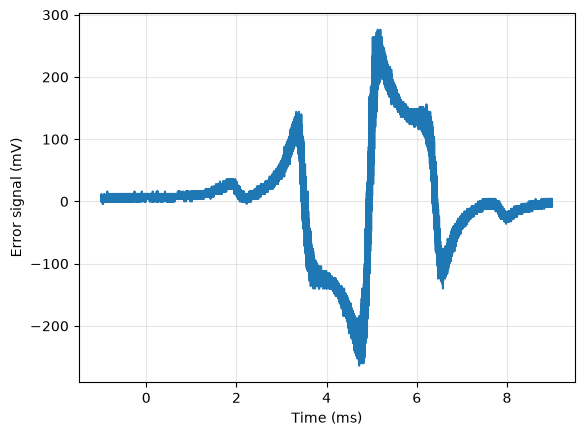

In [10]:
# Plot the unlocked error signal first and identify approximate time windows for
# the carrier and the two sidebands.

fig, axs = plt.subplots(1, 1)
axs.plot(time_unlocked * 1e3, error_signal_unlocked)
axs.set_xlabel('Time (ms)')
axs.set_ylabel('Error signal (mV)')
axs.grid(alpha=0.3)
plt.show()

# TODO: select indices for the carrier and both sidebands.
# carrier_indices = ...
# left_sideband_indices = ...
# right_sideband_indices = ...

# TODO: find the time of the zero crossing or minimum-magnitude error signal
# in each selected region.
# carrier_time = ...
# left_sideband_time = ...
# right_sideband_time = ...

# TODO: use the known 25 MHz sideband spacing to calculate the time-to-frequency
# conversion, center the frequency axis on the carrier, and plot the calibrated signal.
# sideband_spacing_time = ...
# time_to_frequency_conversion = ...
# frequency_unlocked = ...

### Linear PDH response

When the laser is locked, the error signal should remain within the discriminator's linear range. In that range, a voltage fluctuation maps directly to a frequency fluctuation. Estimate the conversion factor from a linear fit around the lock point.

In [18]:
# TODO: choose a small linear region around the carrier.
linear_region = 1.5

#central_indices = ...
#frequency_central = ... 
#error_signal_central = ... 

# TODO: fit error_signal_central versus frequency_central with linregress.
# line = ...
# voltage_to_frequency_factor = ...

# Plot the selected points and fitted line, then report the slope in mV/MHz.

## Frequency deviations in time over a 4 ms interval

Use the local PDH calibration to convert the locked error signal into frequency deviations. Plot the result against time and record the typical and largest excursions.

**Questions to consider:** What information is visible in the time trace, and what information is difficult to extract from it?

In [12]:
# look at the frequency fluctuations in time
#frequency_fluctuations_in_time = error_signal_locked * voltage_to_frequency_factor

# fig, axs = plt.subplots(1, 1)
# axs.plot(time_locked*1e3, frequency_fluctuations_in_time*1e3)
# axs.set_xlabel('Time (ms)')
# axs.set_ylabel('Locked frequency fluctuations (kHz)')
# axs.grid(alpha=0.3)
# plt.show()

## Frequency-noise density analysis

The time trace shows the largest frequency excursions, but it does not reveal how the noise is distributed over Fourier frequency. A frequency-noise density (FND) does: its units are $\mathrm{Hz}/\sqrt{\mathrm{Hz}}$, and integrating its power over a bandwidth gives a frequency variance.

Use the calibrated locked signal to calculate the frequency-noise PSD and plot its square root. 

The oscilloscope bandwidth is 5 MHz, so this measurement cannot characterize noise above that limit. Peaks in the FND can point to technical noise sources, mechanical resonances, or features of the feedback electronics.

### Reflection: frequency-noise density

1. Over which frequency range is the FND trustworthy, and why is the 5 MHz limit important?
2. Which frequency regions contain the largest noise contributions? What physical or electronic sources could produce them?
3. How would changing the PID settings be expected to alter the FND? Compare this with the servo-bump analysis.
4. Why is the FND often more informative than a single linewidth number?

In [14]:
# TODO: convert the locked error signal to frequency fluctuations in Hz.
# frequency_fluctuations_in_time_Hz = ...

# TODO: calculate the frequency-noise PSD with lpsd and plot its square root
# as the frequency-noise density (FND). Restrict the plot to 5 MHz.
# frequencies, psd = ...
# fnd = ...

## Laser lineshape and linewidth

The optical spectrum can be reconstructed from the accumulated phase associated with the measured frequency fluctuations. The equations for this method are summarized on pages 25-33 of the [linewidth analyser manual](../litterature/lwa-10k-100k-manual-2025-06_0007.pdf).

Fit the central lineshape with a Voigt profile. A Gaussian contribution can indicate slow technical noise or frequency drift, while a Lorentzian contribution is associated with white frequency noise. These components are useful diagnostics, but they do not by themselves prove a single noise source.

The linewidth depends on the record length, sampling bandwidth, servo settings, and noise present during the measurement.

In [17]:
# TODO: calculate the sampling frequency and integrate the frequency deviations
# to obtain the phase evolution of the optical field.
# see the equations of pages 28-29 in the linewidth analyser manual.
# fs = ...
# s = ...
# phasor = ...

# TODO: calculate the two-sided optical spectrum with Welch's method.
# Use the full record so the Fourier resolution is as fine as possible.
# nperseg = ...
# frequency_resolution = ...
# freq_fit, spectrum_fit = ...

# TODO: fit the central peak over a 500 kHz window with a Voigt profile.
# The profile has a center, Gaussian width sigma, Lorentzian half-width gamma,
# amplitude, and baseline. Use scipy.special.voigt_profile.


# TODO: calculate the Gaussian FWHM, Lorentzian FWHM, and Voigt FWHM.
# Plot the data and fit on a logarithmic y-axis and interpret which component dominates.